In [2]:
# I want to compare the velocity profiles for the different cases (alongside the MESA profile)
# - velocity (rms)
# - radial velocity (rms)

In [3]:
import numpy as np
import glob
import os
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
r_sun = 6.9570000000000000E+010
r_tot = 5.7671763407229273 * r_sun
r_bot = 52239320762.259705
r_top = 175414301920.61127
Nr = 512
# Ntheta = 360
# Nphi = 720
dr_grid = (r_top - r_bot) / Nr
r_env_init = 0.2836686568328816 * r_tot

In [5]:
absolute_path = "/z2/users/cj517/lscaledir_20M/Om0/production_analysis/strucdir/struc*"
PATTERN = os.path.relpath(absolute_path)

all_files = sorted(glob.glob(PATTERN))
f"{len(all_files)} files found."

'10000 files found.'

In [6]:
subset_files = all_files

In [7]:
headers = ['index', 'radius', 'vel_rms', 'crossing_time_vel', 'crossing_time_hp', 'press_height', 'e_int_spec', 'nabla', 'nabla_adiab', 'pressure', 'temperature', 'entropy', 'entropy_calc', 'e_kin', 'shell_mass', 'density', 'flux_enthalpy', 'flux_e_kin', 'flux_rad', 'flux_diff_scalar', 'vel_1_rms', 'vel_2_rms', 'vel_3_rms', 'vel_1', 'vel_2', 'vel_3', 'theta_1', 'u_phi_average_1', 'theta_2', 'u_phi_average_2', 'theta_3', 'u_phi_average_3', 'theta_4', 'u_phi_average_4', 'theta_5', 'u_phi_average_5', 'theta_6', 'u_phi_average_6', 'theta_7', 'u_phi_average_7', 'theta_8', 'u_phi_average_8', 'theta_9', 'u_phi_average_9', 'theta_10', 'u_phi_average_10', 'theta_11', 'u_phi_average_11', 'angular_momentum', 'scalar', 'flux_mass', 'nabla_mu_equiv', 'flux_heat_instant', 'flux_heat_init', 'flux_heat_ref_prof', 'flux_heat_ref_field', 'brunt_vaissala', 'temperature_std', 'temperature_skew', 'temperature_kurt', 'temperature_rms', 'density_std', 'density_skew', 'density_kurt', 'density_rms', 'temperature_fluct', 'temperature_up_fluct', 'temperature_down_fluct', 'vel_1_correlation', 'buoyancy_work', 'vel_1_std', 'vel_1_skew', 'vel_1_kurt', 'vel_1_rms_duplicate', 'temperature_gradient', 'thermal_conductivity', 'strain_dev_1_1_squared', 'strain_dev_2_2_squared', 'strain_dev_3_3_squared', 'strain_dev_1_2_squared', 'strain_dev_1_3_squared', 'strain_dev_2_3_squared']

In [8]:
def read_file(fname):
    if int(fname[-4:]) % 50 == 0:
        print(fname[-9:],end="\r")
    with open(fname) as f:
        f.readline()
        t = float(f.readline().split()[0])
        # print(t)
        f.readline()
        df = pd.read_csv(f, sep='\s+',
                         names = headers,
                         usecols=["radius", "vel_1_rms", "vel_rms"]
                        )
        df["time"] = t
    return df

In [9]:
# all_data = pd.concat([read_file(f) for f in subset_files])
# print('ALL_DATA_CONCAT: DONE')
# all_data.index.name = 'r_idx'

# # all_data = all_data.set_index(["time", "r_idx"]).sort_index()
# # all_data = all_data.set_index("time",append=True).sort_index()
# all_data = all_data.groupby(["r_idx"]).mean()

../../../../z2/users/cj517/lscaledir_20M/Om0/production_analysis/strucdir/struc*
10000 files found.
using 10000 dumps
ALL_DATA_CONCAT: DONE


KeyError: 'vel_2_rms'

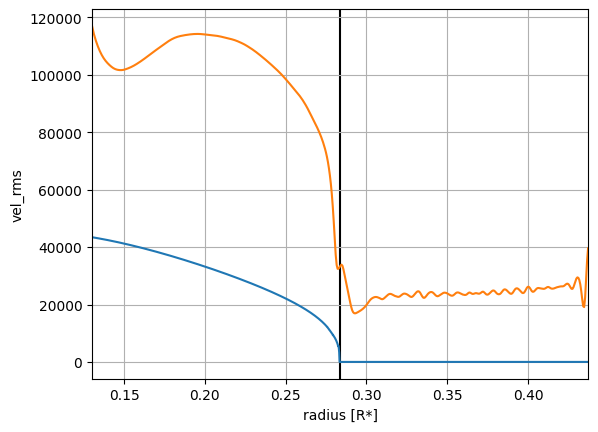

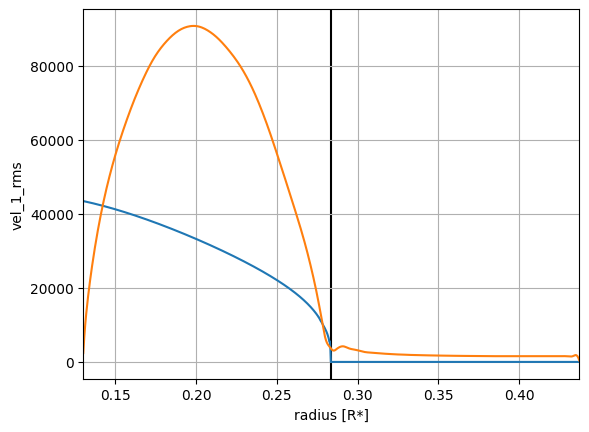

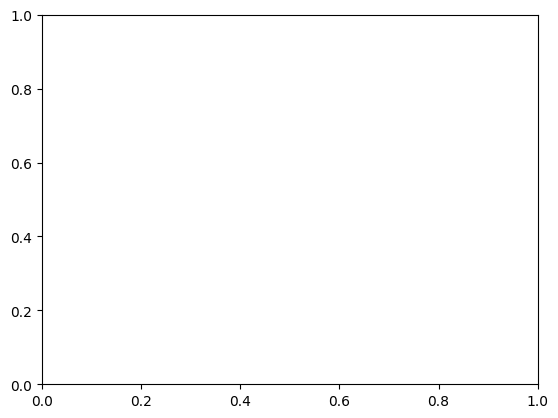

In [10]:
fig1, ax1 = plt.subplots()
fig2, ax2 = plt.subplots()
fig3, ax3 = plt.subplots()
ax1.grid()
ax2.grid()
ax1.set_xlim(r_bot/r_tot, r_top/r_tot)
ax2.set_xlim(r_bot/r_tot, r_top/r_tot)

ax1.set_xlabel("radius [R*]")
ax2.set_xlabel("radius [R*]")
ax1.set_ylabel("vel_rms")
ax2.set_ylabel("vel_1_rms")

ax1.axvline(r_env_init / r_tot, c="k", zorder=-1)
ax2.axvline(r_env_init / r_tot, c="k", zorder=-1)
# plot MESA

MESA_data = sorted(glob.glob('ic_analysis/profile1.data'))
# MESA_headers = 
with open(MESA_data[0], "r") as f:
    f.readline()
    f.readline()
    f.readline()
    f.readline()
    f.readline()
    MESA_headers = f.readline().split()

mesa_df = pd.DataFrame(np.genfromtxt(MESA_data[0],skip_header=6),columns=MESA_headers)
mesa_df = mesa_df.set_index('zone')

mesa_df = mesa_df[mesa_df["radius"].between(r_bot / r_sun, r_top / r_sun)]
ax1.plot(mesa_df["radius"] * r_sun / r_tot, 10**mesa_df["log_conv_vel"], label="MESA (conv_vel)")
ax2.plot(mesa_df["radius"] * r_sun / r_tot, 10**mesa_df["log_conv_vel"], label="MESA (conv_vel)")

vel_max = (10**mesa_df["log_conv_vel"]).max()
vel_1_max = (10**mesa_df["log_conv_vel"]).max()

cases = ["Om0",  "invRo2-5", "invRo2"]
cases = {
    "Om0": {
        "abs_path": "/z2/users/cj517/lscaledir_20M/Om0/production_analysis/strucdir/struc*",
        "label": "Om0 (full)"
            },
    "invRo2-5": {
                 "abs_path": "/z2/users/cj517/lscaledir_20M/invRo2-5/production_analysis/strucdir/struc*",
        "label": "invRo2-5 (full)"
                },
    "invRo2": {
               "abs_path": "/z2/users/cj517/lscaledir_20M/invRo2/stead_state_tests/strucdir/struc*",
                "label": "invRo2 (222 dumps)"
              }
}
for i in cases: # plot for each case
    case = cases[i]
    try:
        if case["skip"] == True:
            continue
    except:
        pass
    PATTERN = os.path.relpath(case["abs_path"])
    print(PATTERN)
    all_files = sorted(glob.glob(PATTERN))
    print(f"{len(all_files)} files found.")
    try:
        spec_files = all_files[-case["num_dumps"]:]
    except:
        spec_files = all_files
    print(f"using {len(spec_files)} dumps")
    # load in data
    all_data = pd.concat([read_file(f) for f in spec_files])
    print('ALL_DATA_CONCAT: DONE')
    all_data.index.name = 'r_idx'
    
    # all_data = all_data.set_index(["time", "r_idx"]).sort_index()
    # all_data = all_data.set_index("time",append=True).sort_index()
    all_data = all_data.groupby(["r_idx"]).mean()

    # check largest velocity
    if all_data["vel_rms"].max() > vel_max:
        vel_max = all_data["vel_rms"].max()
    if all_data["vel_1_rms"].max() > vel_1_max:
        vel_1_max = all_data["vel_1_rms"].max()
    # plot data
    ax1.plot(all_data["radius"] / r_tot, all_data["vel_rms"], label=case["label"])
    ax2.plot(all_data["radius"] / r_tot, all_data["vel_1_rms"], label=case["label"])
    ax3.plot(all_data["radius"] / r_tot, all_data["vel_2_rms"])
ax1.legend()
ax2.legend()
ax1.set_ylim(0,vel_max)
ax2.set_ylim(0,vel_1_max)
fig1.savefig("production_analysis/vel_rms.png")
fig2.savefig("production_analysis/vel_1_rms.png")